# EXP05 — Dropout ở lớp fully connected

So sánh baseline CNN với cùng kiến trúc nhưng thêm `Dropout(p=0.5)` sau ReLU của lớp fully connected ẩn. Không dùng augmentation hay Batch Normalization trong cặp so sánh này; validation không bị biến đổi.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display
from torch import nn

cwd = Path.cwd()
PROJECT_ROOT = next(
    (p for p in (cwd, cwd.parent, cwd / "BTL02") if (p / "train.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục BTL02 hoặc BTL02/notebooks.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from evaluate import evaluate_checkpoint
from models import build_model
from train import run_experiment, select_device

BASELINE_RUN = PROJECT_ROOT / "results/EXP001_Baseline/20261120_122107_175923"
DROPOUT_CONFIG_PATH = PROJECT_ROOT / "configs/exp05_dropout.yaml"
DROPOUT_CONFIG = yaml.safe_load(DROPOUT_CONFIG_PATH.read_text(encoding="utf-8"))
CONTROL_CONFIG = yaml.safe_load((BASELINE_RUN / "config.yaml").read_text(encoding="utf-8"))

## Kiểm soát biến số

Giữ nguyên split 80/20, seed 42, baseline CNN, 30 epoch, batch 64, Adam và learning rate 0,001. Khác biệt duy nhất trong kiến trúc là Dropout p=0.5 sau ReLU lớp ẩn. So sánh với baseline không augmentation và không BatchNorm.

In [2]:
shared_keys = ("data_dir", "epochs", "batch_size", "learning_rate", "seed", "device")
for key in shared_keys:
    if CONTROL_CONFIG[key] != DROPOUT_CONFIG[key]:
        raise ValueError(f"Cấu hình Dropout khác baseline ở {key!r}.")
if CONTROL_CONFIG.get("augmentation") or DROPOUT_CONFIG.get("augmentation"):
    raise ValueError("EXP05 yêu cầu tắt augmentation ở cả hai lượt.")
if CONTROL_CONFIG.get("model", "baseline") != "baseline":
    raise ValueError("Run đối chứng phải dùng baseline CNN.")

models = {
    "Baseline (không Dropout)": build_model("baseline"),
    "Baseline + Dropout(0.5)": build_model("baseline_dropout"),
}
architecture = pd.DataFrame({
    name: {
        "Số tham số": sum(p.numel() for p in model.parameters()),
        "Số lớp Conv": sum(isinstance(m, nn.Conv2d) for m in model.modules()),
        "Dropout p": next((m.p for m in model.modules() if isinstance(m, nn.Dropout)), 0),
    }
    for name, model in models.items()
}).T
display(architecture)
print("Các thiết lập huấn luyện khớp nhau; chỉ kiến trúc có/không Dropout khác nhau.")

,Số tham số,Số lớp Conv,Dropout p
Baseline (không Dropout),683527.0,3.0,0.0
Baseline + Dropout(0.5),683527.0,3.0,0.5


Các thiết lập huấn luyện khớp nhau; chỉ kiến trúc có/không Dropout khác nhau.


## Dùng lại run hoặc huấn luyện Dropout

Baseline đối chứng dùng kết quả đã lưu. Để chạy lại EXP05, giữ `DROPOUT_RUN = None`; sau khi có run hoàn chỉnh, có thể điền đường dẫn tương đối để notebook dùng lại checkpoint.

In [3]:
DROPOUT_RUN = "results/EXP05/dropout/baseline_dropout/20261126_224137_190818"

runs = {"Baseline (không Dropout)": BASELINE_RUN}
if DROPOUT_RUN is None:
    dropout_run = run_experiment(DROPOUT_CONFIG_PATH)
else:
    dropout_run = Path(DROPOUT_RUN)
    if not dropout_run.is_absolute():
        dropout_run = PROJECT_ROOT / dropout_run
    if not (dropout_run / "best.pth").is_file():
        raise FileNotFoundError(f"Không tìm thấy checkpoint: {dropout_run / 'best.pth'}")
runs["Baseline + Dropout(0.5)"] = dropout_run
for name, run in runs.items():
    print(f"{name} · {run.relative_to(PROJECT_ROOT)}")

Baseline (không Dropout) · results\EXP001_Baseline\20261120_122107_175923
Baseline + Dropout(0.5) · results\EXP05\dropout\baseline_dropout\20261126_224137_190818


## Đánh giá trên validation

Dùng checkpoint có validation loss thấp nhất. Macro F1 và F1 từng lớp bổ sung cho accuracy tổng thể; mọi chỉ số dưới đây là validation, không phải test.

In [4]:
evaluations = {}
rows = []
for name, run in runs.items():
    run_config = yaml.safe_load((run / "config.yaml").read_text(encoding="utf-8"))
    training = json.loads((run / "training.json").read_text(encoding="utf-8"))
    evaluation_path = run / "evaluation.json"
    if evaluation_path.is_file():
        saved = json.loads(evaluation_path.read_text(encoding="utf-8"))
    else:
        saved = None
    if saved is None or saved.get("split") != "validation":
        saved = evaluate_checkpoint(
            run,
            PROJECT_ROOT / run_config["data_dir"],
            run_config["batch_size"],
            select_device(run_config.get("device", "auto")),
            split="validation",
        )
    evaluations[name] = saved
    rows.append({
        "Mô hình": name,
        "Best epoch": training["best_epoch"],
        "Validation loss": training["best_val_loss"],
        "Validation accuracy": saved["accuracy"],
        "Validation macro F1": saved["macro_f1"],
        "Thời gian train (giây)": training["training_seconds"],
        "Thiết bị": training["hardware"],
    })
results = pd.DataFrame(rows).set_index("Mô hình")
display(results.round(4))

,Best epoch,Validation loss,Validation accuracy,Validation macro F1,Thời gian train (giây),Thiết bị
Mô hình,,,,,,
Baseline (không Dropout),8,1.1995,0.5521,0.4861,1570.0759,CPU
Baseline + Dropout(0.5),10,1.2093,0.5482,0.4544,1632.0342,CPU


## Learning curves

Đường loss và accuracy cho thấy Dropout ảnh hưởng thế nào đến quá trình fit và khoảng cách giữa train/validation.

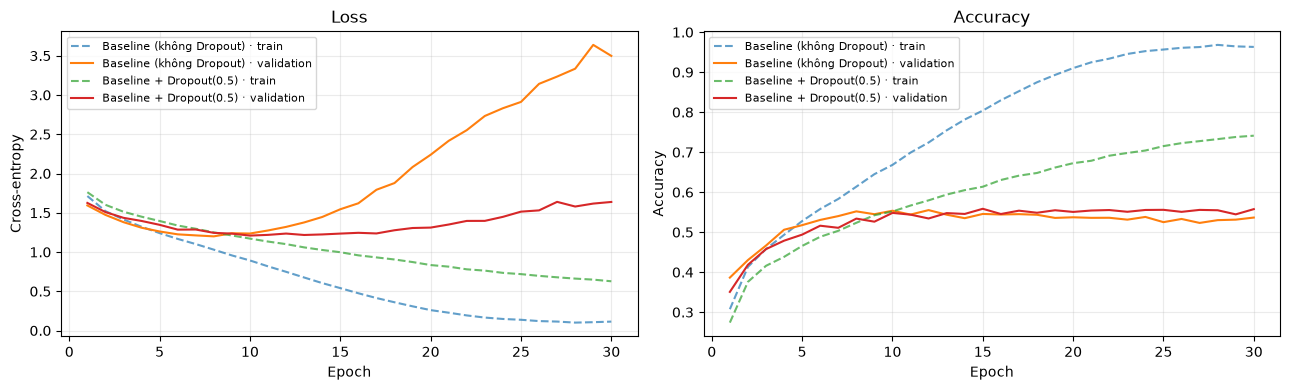

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, run in runs.items():
    history = pd.read_csv(run / "history.csv")
    axes[0].plot(history["epoch"], history["train_loss"], linestyle="--", alpha=0.7, label=f"{name} · train")
    axes[0].plot(history["epoch"], history["val_loss"], label=f"{name} · validation")
    axes[1].plot(history["epoch"], history["train_accuracy"], linestyle="--", alpha=0.7, label=f"{name} · train")
    axes[1].plot(history["epoch"], history["val_accuracy"], label=f"{name} · validation")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Confusion matrix và F1 theo lớp

Dùng các hình validation đã lưu trong từng thư mục run để xem lớp nào được cải thiện hoặc suy giảm.

,Baseline (không Dropout),Baseline + Dropout(0.5)
Angry,0.4380,0.4636
Disgust,0.2521,0.0000
Fear,0.3494,0.3096
Happy,0.7478,0.7594
Sad,0.4467,0.4361
Surprise,0.6544,0.6769
Neutral,0.5145,0.5354


### Baseline (không Dropout)

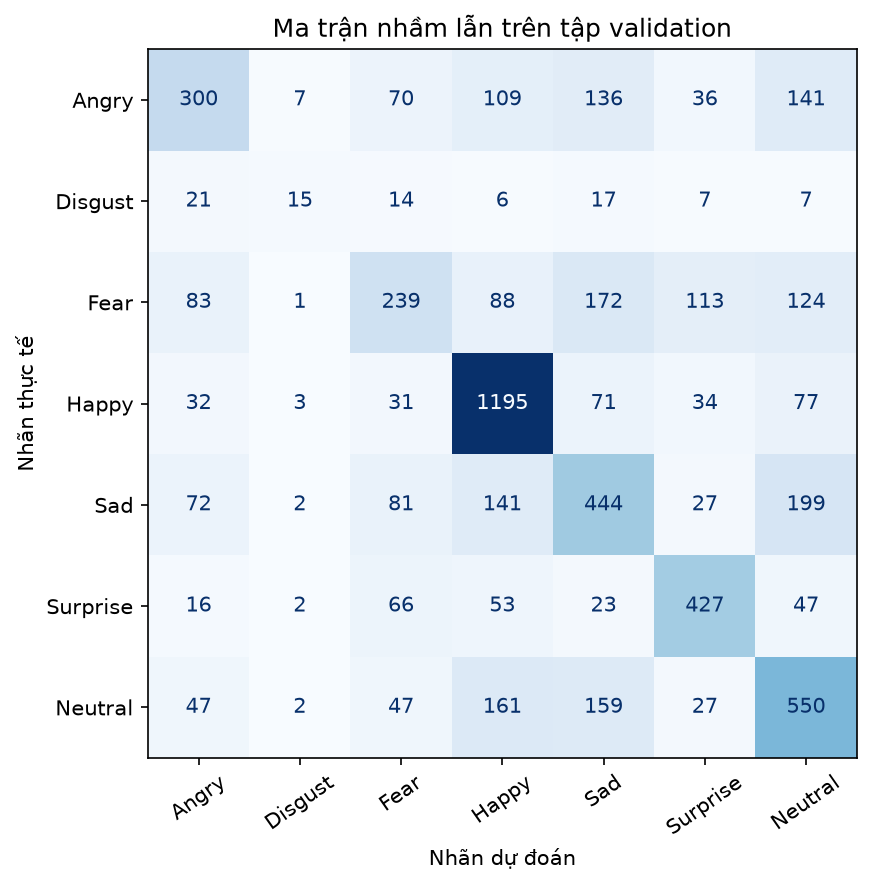

### Baseline + Dropout(0.5)

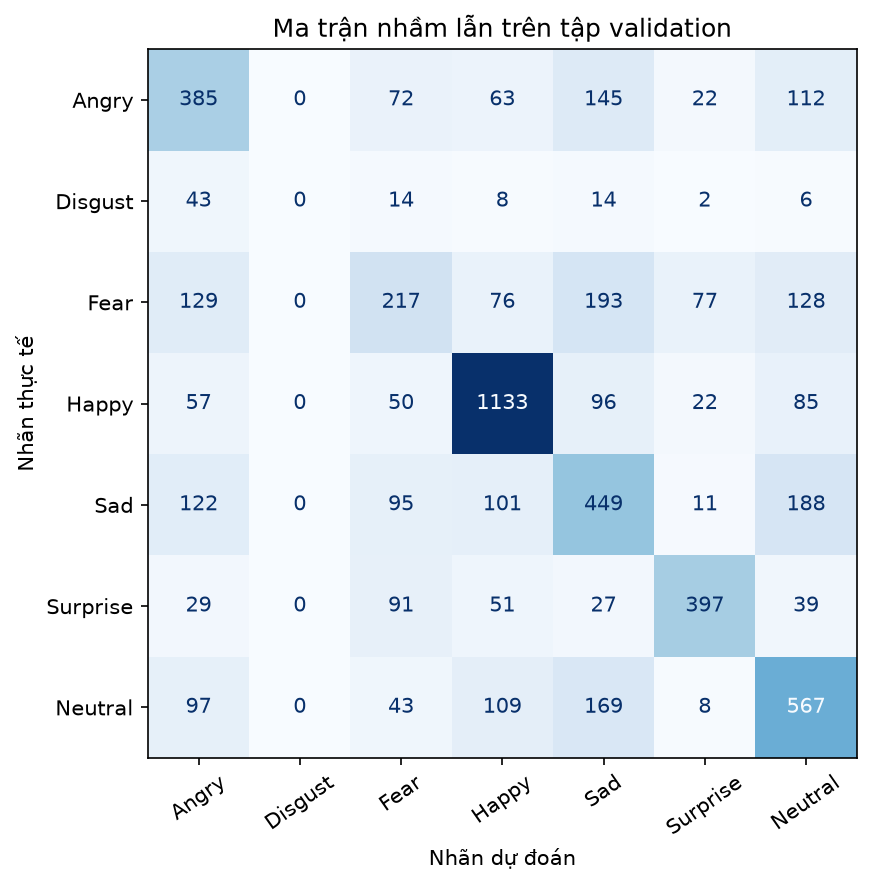

In [6]:
class_f1 = pd.DataFrame({
    name: {emotion: values["f1-score"] for emotion, values in result["per_class"].items()}
    for name, result in evaluations.items()
})
display(class_f1.round(4))
for name, run in runs.items():
    display(Markdown(f"### {name}"))
    display(Image(filename=str(run / "confusion_matrix.png"), width=650))

## Nhận xét

So sánh validation loss, accuracy, macro F1, F1 từng lớp và thời gian train. Dropout có thể làm giảm train accuracy nhưng có ích nếu validation tốt hơn và khoảng cách train/validation thu hẹp. Vì mỗi cấu hình hiện có một seed, ghi nhận kết quả là một lượt thực nghiệm; chưa đánh giá test.